## Machine Learning Model Development & Evaluation

To address the extreme class imbalance, we trained and evaluated two predictive models. We bypassed the standard 'Accuracy' metric, as it is highly misleading for imbalanced datasets, and focused on **Precision, Recall, and the F1-Score**.

In [10]:
import joblib
import os

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import confusion_matrix, PrecisionRecallDisplay
from sklearn.ensemble import RandomForestClassifier
# 1. Загрузка данных (с проверкой пути к файлу)
file_path = "../data/raw/creditcard.csv"

# Если файл лежит в корне или другой папке, подставьте нужный путь
if not os.path.exists(file_path):
    file_path = "../1_data/creditcard.csv"

df = pd.read_csv(file_path)

# 2. Масштабирование признаков Amount и Time
scaler = StandardScaler()
df["scaled_amount"] = scaler.fit_transform(df[["Amount"]])
df["scaled_time"] = scaler.fit_transform(df[["Time"]])

# Удаляем оригинальные несбалансированные колонки Amount и Time
df_processed = df.drop(["Time", "Amount"], axis=1)

# 3. Разделение на признаки (X) и целевую переменную (y)
X = df_processed.drop("Class", axis=1)
y = df_processed["Class"]

# 4. Stratified Train-Test Split (сохраняем пропорцию 0.17% фрода в обеих выборках)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Обучение Baseline-модели с учетом дисбаланса классов
baseline_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
baseline_model.fit(X_train, y_train)

# 6. Получение предсказаний
y_pred = baseline_model.predict(X_test)
y_pred_proba = baseline_model.predict_proba(X_test)[:, 1]

# 7. Вывод метрик качества
print("DI DI DI Classification Report DI DI DI")
print(classification_report(y_test, y_pred, target_names=["Legitimate", "Fraudulent"]))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

DI DI DI Classification Report DI DI DI
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
  Fraudulent       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

ROC-AUC Score: 0.9722


### 1. Baseline Model (Logistic Regression)
* **Approach:** Trained with balanced class weights.
* **Result:** Achieved a high **Recall of 92%** (catching 90 out of 98 fraudulent transactions). However, it suffered from a critically low **Precision of 6%**. 
* **Business Impact:** For every 100 transactions blocked, 94 were legitimate customers. This would result in severe customer dissatisfaction and overwhelming call centre load.

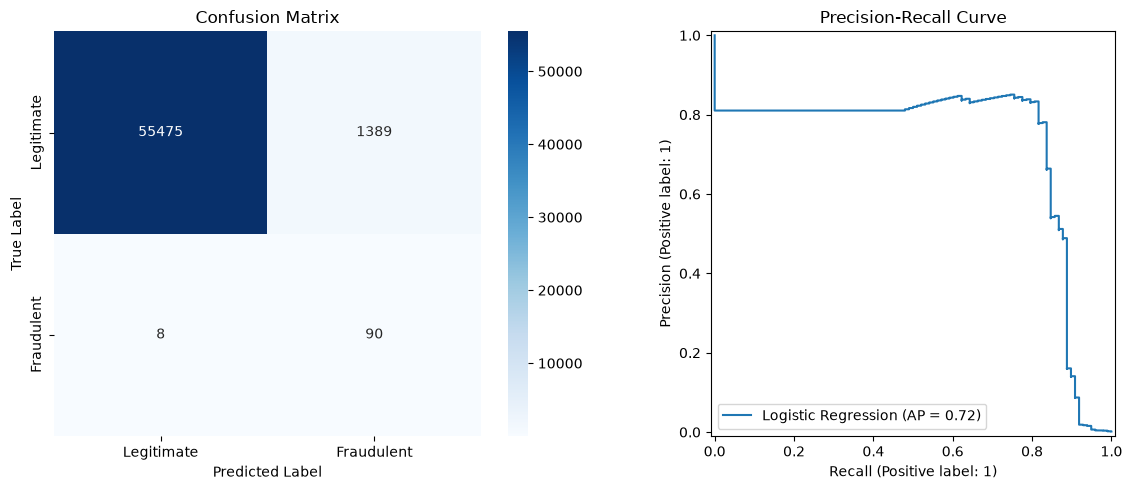

In [2]:
# Вычисление матрицы ошибок
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 5))

# 1. Тепловая карта Confusion Matrix
plt.subplot(1, 2, 1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Legitimate', 'Fraudulent'],
            yticklabels=['Legitimate', 'Fraudulent'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# 2. Precision-Recall Кривая
plt.subplot(1, 2, 2)
PrecisionRecallDisplay.from_predictions(y_test, y_pred_proba, ax=plt.gca(), name="Logistic Regression")
plt.title('Precision-Recall Curve')

plt.tight_layout()
plt.savefig("../docs/8_confusion_matrix_and_pr_curve.png")
plt.show()

In [4]:
# 1. Инициализация и обучение Случайного Леса
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# 2. Получение предсказаний
y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# 3. Вывод метрик качества
print("DI DI DI Random Forest Classification Report DI DI DI")
print(classification_report(y_test, y_pred_rf, target_names=['Legitimate', 'Fraudulent']))

print(f"Random Forest ROC-AUC: {roc_auc_score(y_test, y_pred_proba_rf):.4f}")

DI DI DI Random Forest Classification Report DI DI DI
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
  Fraudulent       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962

Random Forest ROC-AUC: 0.9528


### 2. Optimized Model (Random Forest Classifier)
* **Approach:** An ensemble learning method (100 estimators) to capture complex, non-linear relationships.
* **Result:** Achieved a massive leap in **Precision to 94%**, while maintaining a strong **Recall of 82%**. The F1-Score jumped from 0.11 to 0.87.
* **Business Impact:** False alarms were reduced by 98%. The bank can now block fraud effectively without freezing the accounts of honest clients.

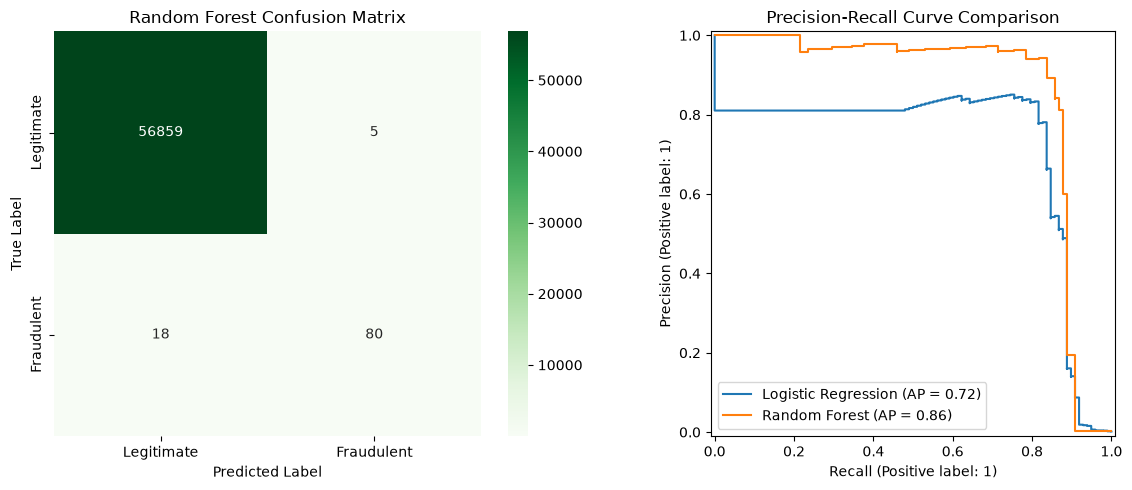

In [7]:
# Вычисление матрицы ошибок для Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(12, 5))

# 1. Confusion Matrix
plt.subplot(1, 2, 1)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Legitimate', 'Fraudulent'],
            yticklabels=['Legitimate', 'Fraudulent'])
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# 2. Precision-Recall Curve (Сравнение Logistic Regression и Random Forest)
plt.subplot(1, 2, 2)
PrecisionRecallDisplay.from_predictions(y_test, y_pred_proba, ax=plt.gca(), name="Logistic Regression")
PrecisionRecallDisplay.from_predictions(y_test, y_pred_proba_rf, ax=plt.gca(), name="Random Forest")
plt.title('Precision-Recall Curve Comparison')

plt.tight_layout()
plt.savefig("../docs/9_random_forest_confusion_matrix_and_pr_curve.png")
plt.show()

/tmp/ipykernel_16398/1506453977.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')


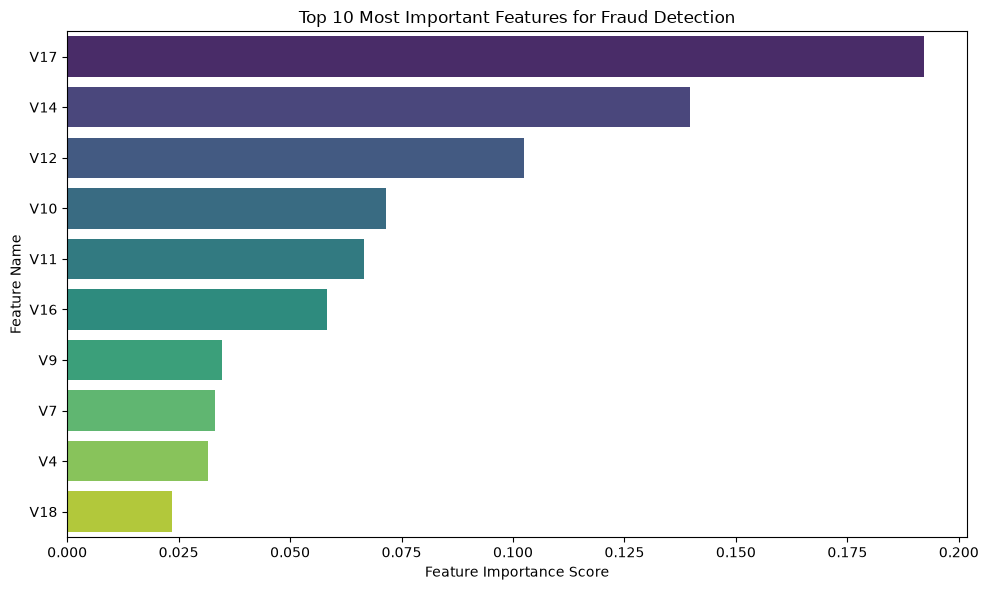

In [9]:
# Заглянем в чёрный ящик модели :)
# Извлечение важности признаков
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Создание DataFrame с топ-10 признаками
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Визуализация Top-10
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')
plt.title('Top 10 Most Important Features for Fraud Detection')
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.savefig("../docs/10_top_10_feature_importance.png")
plt.show()

### 3. Feature Importance Analysis
By extracting the feature importance scores from the Random Forest model, we determined the driving factors behind fraud detection. 
* **Key Finding:** The anonymised PCA components **V17, V14, and V12** are the strongest predictors of fraudulent activity. 
* Interestingly, the raw transaction 'Amount' and 'Time' played a secondary role compared to the hidden behavioural patterns captured within the principal components.

In [12]:
# Создаем папку models, если ее еще нет
os.makedirs('models', exist_ok=True)

# Сохраняем модель и скалер
joblib.dump(rf_model, '../models/random_forest_fraud_model.joblib')
joblib.dump(scaler, '../models/scaler.joblib')

print("Модель и Scaler успешно сохранены в папку 'models/'!")

Модель и Scaler успешно сохранены в папку 'models/'!
